In [19]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [20]:
TEXT_COL = "sentence"
LABEL_COL = "label"  # 预测配对读取原始类别名称；labels 的 one-hot 编码保留

SAMPLE_SIZE = 200
NUM_QUANTILES = 100
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
# 明确使用第一块 CUDA GPU；不可用时停止，不静默退回 CPU。
DEVICE = "cuda:0"


In [21]:

from pathlib import Path
DATA_DIR = Path.cwd() / "data" / "RHEOLOGY"
if not DATA_DIR.is_dir():
    DATA_DIR = Path.cwd() / "Rheology" / "data" / "RHEOLOGY"
train_df = pd.read_json(
    DATA_DIR / "train.json",
    lines=True,
)

dev_df = pd.read_json(
    DATA_DIR / "dev.json",
    lines=True,
)

print("Train:", train_df.shape)
print("Dev:", dev_df.shape)

display(train_df.head())

Train: (1612, 3)
Dev: (403, 3)


,id,sentence,label
0,0,"Kim et al., 2006b), has conduced to confused i...",BIODEGRAD_PROP
1,1,A similar type of physical damage in the hydro...,BIODEGRAD_POLY
2,2,"At pH 1 and 9, the overall observations were s...",BIODEGRAD_PROP
3,3,"As expected, the kinetic constants showed a pr...",BIODEGRAD_PROP
4,4,This can be observed from Figure 9. The cracks...,BIODEGRAD_PROP


In [22]:

# 固定类别顺序：仅从训练集建立映射，验证集沿用。
import numpy as np

if train_df["label"].isna().any() or dev_df["label"].isna().any():
    raise ValueError("Missing labels detected; resolve them before encoding")
if any(frame["label"].astype(str).str.strip().eq("").any() for frame in [train_df, dev_df]):
    raise ValueError("Empty labels detected; resolve them before encoding")
label_names = sorted(train_df["label"].unique().tolist())
label_to_id = {label: i for i, label in enumerate(label_names)}
id_to_label = dict(enumerate(label_names))
NUM_LABELS = len(label_names)
unknown_labels = set(dev_df["label"]) - set(label_names)
if unknown_labels:
    raise ValueError(f"Dev labels absent from train: {sorted(unknown_labels)}")

for frame in [train_df, dev_df]:
    # 单标签多分类：CrossEntropyLoss 使用整数 label_id。
    frame["label_id"] = frame["label"].map(label_to_id).astype(int)
    # 便于查看的向量编码；单标签时每行只有一个 1，即 one-hot。
    frame["labels"] = np.eye(NUM_LABELS, dtype=np.int8)[frame["label_id"].to_numpy()].tolist()

print("Number of classes:", NUM_LABELS)
display(pd.DataFrame({"label": label_names, "label_id": range(NUM_LABELS)}))
display(train_df[["sentence", "label", "label_id", "labels"]].head(10))


Number of classes: 5


,label,label_id
0,BIODEGRAD_POLY,0
1,BIODEGRAD_PROP,1
2,MECHANICAL_PROP,2
3,POLY_STRUC,3
4,RHEOLOGICAL_PROP,4


,sentence,label,label_id,labels
0,"Kim et al., 2006b), has conduced to confused i...",BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
1,A similar type of physical damage in the hydro...,BIODEGRAD_POLY,0,"[1, 0, 0, 0, 0]"
2,"At pH 1 and 9, the overall observations were s...",BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
3,"As expected, the kinetic constants showed a pr...",BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
4,This can be observed from Figure 9. The cracks...,BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
5,The synthesis of lactic acid into high−molecul...,POLY_STRUC,3,"[0, 0, 0, 1, 0]"
6,Figure 1 Open in figure viewer PowerPoint Resi...,BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
7,Eq. 5 corresponds to the initial viscosity inc...,RHEOLOGICAL_PROP,4,"[0, 0, 0, 0, 1]"
8,Mass spectroscopy was used to determine the na...,BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"
9,the degradation process can occur during the m...,BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]"


In [23]:
df = pd.concat(
    [train_df, dev_df],
    ignore_index=True,
)

print(df.shape)

(2015, 5)


In [24]:
def sample_from_length_groups(
    df,
    text_col,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
    return_grouped=False,
):
    """按文本长度分位组无放回抽样，不修改输入或依赖标签格式。

    默认长度是空白分隔词数。length_fn 可传入接收单篇文本并返回长度的函数，
    例如 len（字符数），或 lambda text: len(tokenizer.encode(text))。
    返回原有列和原始文本，并新增 length_col 和 group_col（Q1、Q2……）。
    缺失、空白文本不参与抽样。return_grouped=True 时返回
    (sampled_df, grouped_df)，后者包含全部有效文章的长度和分组，供后续复用。
    """
    if len({text_col, length_col, group_col}) != 3:
        raise ValueError("Text, length and group column names must be different")
    if length_col in df.columns or group_col in df.columns:
        raise ValueError("Length/group output columns already exist; choose unused output names")
    if text_col not in df.columns:
        raise ValueError(f"Missing text column: {text_col}")
    for name, value in [("sample_size", sample_size), ("num_quantiles", num_quantiles)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be a positive integer")

    text = df[text_col].fillna("").astype(str).str.strip()
    pool = df.loc[text.ne("")].copy().reset_index(drop=True)
    text = text.loc[text.ne("")].reset_index(drop=True)
    if sample_size > len(pool):
        raise ValueError(f"Requested {sample_size} rows, but only {len(pool)} valid texts")

    lengths = text.str.split().str.len() if length_fn is None else text.map(length_fn)
    lengths = pd.to_numeric(lengths, errors="raise")
    if not np.isfinite(lengths.to_numpy(dtype=float)).all() or lengths.lt(0).any():
        raise ValueError("Text lengths must be finite, non-negative numbers")

    q = min(num_quantiles, sample_size, lengths.nunique())
    # 相同长度不拆组；所有文本长度相同时使用一个组。
    groups = (
        pd.Series(np.zeros(len(pool), dtype=int))
        if q <= 1 else pd.qcut(lengths, q=q, labels=False, duplicates="drop")
    )
    # 分组基于完整有效数据，而不是抽样后的数据。
    pool[length_col] = lengths.to_numpy()
    pool[group_col] = pd.Categorical(
        groups.map(lambda group: f"Q{int(group) + 1}"),
        categories=[f"Q{int(group) + 1}" for group in sorted(groups.unique())],
        ordered=True,
    )
    group_indices = list(groups.groupby(groups, sort=True).groups.values())
    rng = np.random.default_rng(random_seed)
    base_n = sample_size // len(group_indices)
    selected = []
    for indices in group_indices:
        selected.extend(rng.choice(
            np.asarray(indices), size=min(base_n, len(indices)), replace=False
        ).tolist())

    # 分位组不足或较小时，从未选中的行补足目标数量。
    remaining_n = sample_size - len(selected)
    if remaining_n:
        remaining_indices = np.setdiff1d(np.arange(len(pool)), selected)
        selected.extend(rng.choice(remaining_indices, size=remaining_n, replace=False).tolist())
    rng.shuffle(selected)
    sampled_df = pool.iloc[selected].copy().reset_index(drop=True)
    sampled_lengths = lengths.iloc[selected]
    print("Valid texts:", len(pool))
    print("Length groups:", len(group_indices))
    print("Actual sample size:", len(sampled_df))
    print("Length measure:", "whitespace word count" if length_fn is None else "custom length_fn")
    print("Sample length min / mean / max:",
          sampled_lengths.min(), sampled_lengths.mean(), sampled_lengths.max())
    return (sampled_df, pool) if return_grouped else sampled_df


In [25]:
sampled_df, grouped_df = sample_from_length_groups(
    df=df,
    text_col=TEXT_COL,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    random_seed=RANDOM_SEED,
    length_col="length",
    group_col="quantiles",
    return_grouped=True,
)
display(sampled_df.head())

# grouped_df：全部有效文章；sampled_df：抽样文章，两者均保留长度和分组。
display(grouped_df[[TEXT_COL, "length", "quantiles"]].head())


Valid texts: 2015
Length groups: 35
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 12 36.21 73


,id,sentence,label,label_id,labels,length,quantiles
0,295,Specific gravity Glass−Transition Type of PDLL...,POLY_STRUC,3,"[0, 0, 0, 1, 0]",64,Q36
1,770,The composition of PEG decreased very graduall...,BIODEGRAD_POLY,0,"[1, 0, 0, 0, 0]",46,Q29
2,231,Reed and Gilding [18] examined the effect of t...,BIODEGRAD_PROP,1,"[0, 1, 0, 0, 0]",27,Q9
3,929,"Also, as for distilled water experiments, the ...",POLY_STRUC,3,"[0, 0, 0, 1, 0]",31,Q14
4,358,The aim of the present work was to investigate...,POLY_STRUC,3,"[0, 0, 0, 1, 0]",50,Q32


,sentence,length,quantiles
0,"Kim et al., 2006b), has conduced to confused i...",34,Q17
1,A similar type of physical damage in the hydro...,27,Q9
2,"At pH 1 and 9, the overall observations were s...",34,Q17
3,"As expected, the kinetic constants showed a pr...",29,Q12
4,This can be observed from Figure 9. The cracks...,29,Q12


In [26]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable: select the CUDA-enabled Python environment")
    device = torch.device(DEVICE)
    print("GPU:", torch.cuda.get_device_name(device), flush=True)

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [27]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [28]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [29]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [30]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    """接收类别字符串或类别名称列表；不将 hot 向量误当成类别集合。"""
    label_sets = []
    for document_labels in labels:
        if isinstance(document_labels, str):
            values = [document_labels]
        elif isinstance(document_labels, (list, tuple, set, np.ndarray)):
            values = list(document_labels)
        else:
            raise ValueError("Use class names or lists of class names for prediction pairs")
        if not values or not all(isinstance(value, str) and value.strip() for value in values):
            raise ValueError(
                "Expected non-empty class names, not one-hot/multi-hot vectors. "
                "For Rheology set LABEL_COL='label', not 'labels'."
            )
        label_sets.append(set(values))
    return label_sets


In [31]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [32]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [33]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [34]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [35]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=None,
    label_col=None,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
):
    if text_col is None or label_col is None:
        raise ValueError("Pass text_col and label_col explicitly for the current dataset")
    missing = {text_col, label_col} - set(grouped_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    convert_to_label_sets(grouped_df[label_col].tolist())
    if num_repetitions < 1:
        raise ValueError("num_repetitions must be at least 1")
    if length_col == label_col or group_col == label_col:
        raise ValueError("Length/group column names must differ from label_col")
    if models is None:
        models = MODELS

    # 允许传入原始 df 或已经带长度分组的 grouped_df。
    # 在副本上移除派生列，由统一 sampler 按当前参数重新生成。
    sampling_pool = grouped_df.drop(columns=[length_col, group_col], errors="ignore").copy()
    # 保留可追踪的原始行标识，不使用抽样后重新编号的 index。
    if "document_id" not in sampling_pool.columns:
        if not sampling_pool.index.is_unique:
            raise ValueError("Provide a unique document_id when the input index is not unique")
        sampling_pool["document_id"] = sampling_pool.index.map(str)


    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=sampling_pool,
                text_col=text_col,
                length_fn=length_fn,
                length_col=length_col,
                group_col=group_col,
                return_grouped=False,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [36]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/3
Repetition seed: 383329927
Valid texts: 2015
Length groups: 35
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 12 36.58 83
Actual sample size: 200
Label counts:
label
BIODEGRAD_POLY      76
BIODEGRAD_PROP      42
MECHANICAL_PROP      9
POLY_STRUC          67
RHEOLOGICAL_PROP     6
Name: count, dtype: int64
Number of represented labels: 5

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GPU: NVIDIA GeForce RTX 5080
Model: google-bert/bert-base-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 5973
Number of label-set pair types: 10
Total unique between-label document pairs: 13927
Same-label target size: 5973
Different-label pair types: 10
Base sample per diff-label pair: 597

Summary:
Same mean: 0.7801089303668731
Different mean: 0.770462261997354
Mean gap: 0.009646668369518977
Same eta: -0.2731791546422393
Different eta: -0.2604566675826018
Different |eta|: 0.2604566675826018
Eta gap: -0.012722487059637501
Chi-square distance: 0.007690562273676285
Chi-square bootstrap std: 0.0010400434864598503

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (55 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: NVIDIA GeForce RTX 5080
Model: recobo/chemical-bert-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 5376
Number of label-set pair types: 10
Total unique between-label document pairs: 14524
Same-label target size: 5376
Different-label pair types: 10
Base sample per diff-label pair: 537

Summary:
Same mean: 0.8614908902174128
Different mean: 0.8539306887428254
Mean gap: 0.007560201474587355
Same eta: -0.3116624219378445
Different eta: -0.3139699549851008
Different |eta|: 0.3139699549851008
Eta gap: 0.0023075330472562766
Chi-square distance: 0.014229074739548
Chi-square bootstrap std: 0.0014822044915518296


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.780109,-0.273179,0.273179,5973,0.770462,0.000719,-0.260457,0.019553,0.260457,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
1,allenai/scibert_scivocab_uncased,0.833322,-0.500119,0.500119,5973,0.825615,0.000687,-0.475725,0.015316,0.475725,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
2,nlpaueb/legal-bert-base-uncased,0.901764,-0.341671,0.341671,5973,0.900330,0.000314,-0.435050,0.017758,0.435050,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
3,ahmedrachid/FinancialBERT,0.816349,-0.433814,0.433814,5973,0.814055,0.000711,-0.467622,0.017811,0.467622,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
4,Lianglab/PharmBERT-uncased,0.780043,-0.353389,0.353389,5973,0.774169,0.000786,-0.419643,0.015023,0.419643,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
5,recobo/agriculture-bert-uncased,0.852407,-0.366235,0.366235,5973,0.839090,0.000621,-0.399919,0.016309,0.399919,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
6,recobo/chemical-bert-uncased,0.858725,-0.260994,0.260994,5973,0.854653,0.000465,-0.396728,0.017582,0.396728,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
7,google-bert/bert-base-uncased,0.770230,-0.295477,0.295477,5701,0.768913,0.000730,-0.269002,0.022484,0.269002,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5
8,allenai/scibert_scivocab_uncased,0.828013,-0.387515,0.387515,5701,0.828874,0.000564,-0.394716,0.019316,0.394716,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5
9,nlpaueb/legal-bert-base-uncased,0.896472,-0.404935,0.404935,5701,0.899029,0.000330,-0.462124,0.017635,0.462124,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5


In [37]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.780109,-0.273179,0.273179,5973,0.770462,0.000719,-0.260457,0.019553,0.260457,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
1,allenai/scibert_scivocab_uncased,0.833322,-0.500119,0.500119,5973,0.825615,0.000687,-0.475725,0.015316,0.475725,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
2,nlpaueb/legal-bert-base-uncased,0.901764,-0.341671,0.341671,5973,0.900330,0.000314,-0.435050,0.017758,0.435050,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
3,ahmedrachid/FinancialBERT,0.816349,-0.433814,0.433814,5973,0.814055,0.000711,-0.467622,0.017811,0.467622,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
4,Lianglab/PharmBERT-uncased,0.780043,-0.353389,0.353389,5973,0.774169,0.000786,-0.419643,0.015023,0.419643,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
5,recobo/agriculture-bert-uncased,0.852407,-0.366235,0.366235,5973,0.839090,0.000621,-0.399919,0.016309,0.399919,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
6,recobo/chemical-bert-uncased,0.858725,-0.260994,0.260994,5973,0.854653,0.000465,-0.396728,0.017582,0.396728,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,5
7,google-bert/bert-base-uncased,0.770230,-0.295477,0.295477,5701,0.768913,0.000730,-0.269002,0.022484,0.269002,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5
8,allenai/scibert_scivocab_uncased,0.828013,-0.387515,0.387515,5701,0.828874,0.000564,-0.394716,0.019316,0.394716,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5
9,nlpaueb/legal-bert-base-uncased,0.896472,-0.404935,0.404935,5701,0.899029,0.000330,-0.462124,0.017635,0.462124,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,5


In [38]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.781287,0.004774,0.775075,0.003551,0.000707,-0.332617,0.018459,0.332617,0.018459,...,0.019190,0.042619,0.025017,0.011943,0.007509,0.001321,5683.333333,5683.333333,5.0,3
1,ahmedrachid/FinancialBERT,0.816134,0.004686,0.814383,0.001252,0.000654,-0.387367,0.041905,0.387367,0.041905,...,0.018756,0.036171,0.020040,0.003821,0.002330,0.000723,5683.333333,5683.333333,5.0,3
2,allenai/scibert_scivocab_uncased,0.832593,0.004262,0.827103,0.001648,0.000610,-0.380778,0.122849,0.380778,0.122849,...,0.018159,0.019432,0.004820,0.015037,0.010256,0.001452,5683.333333,5683.333333,5.0,3
3,google-bert/bert-base-uncased,0.778373,0.007429,0.770696,0.001910,0.000732,-0.285125,0.011234,0.285125,0.011234,...,0.021193,0.036578,0.022257,0.008913,0.002860,0.001146,5683.333333,5683.333333,5.0,3
4,nlpaueb/legal-bert-base-uncased,0.901071,0.004294,0.899780,0.000673,0.000319,-0.349648,0.051762,0.349648,0.051762,...,0.018791,0.055814,0.038292,0.006439,0.005879,0.000924,5683.333333,5683.333333,5.0,3
5,recobo/agriculture-bert-uncased,0.850352,0.004511,0.842178,0.003258,0.000547,-0.330104,0.061770,0.330104,0.061770,...,0.018826,0.042031,0.031917,0.025708,0.013676,0.001857,5683.333333,5683.333333,5.0,3
6,recobo/chemical-bert-uncased,0.859078,0.002257,0.853844,0.000855,0.000456,-0.242805,0.079527,0.242805,0.079527,...,0.018965,0.072520,0.060347,0.008624,0.005106,0.001119,5683.333333,5683.333333,5.0,3


In [39]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,3,3,4,4,3,3
1,ahmedrachid/FinancialBERT,5,3,6,6,1,1,6,7
2,allenai/scibert_scivocab_uncased,4,4,4,4,2,3,7,2
3,google-bert/bert-base-uncased,7,1,2,2,6,7,5,4
4,nlpaueb/legal-bert-base-uncased,1,7,7,7,3,2,2,6
5,recobo/agriculture-bert-uncased,3,5,1,1,5,5,4,1
6,recobo/chemical-bert-uncased,2,6,5,5,7,6,1,5


In [40]:
from pathlib import Path
import seaborn as sns

PROJECT_DIR = DATA_DIR.parent.parent
PLOT_DIR = PROJECT_DIR / "results" / "rank_prediction"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
real_ranking_df = pd.read_csv(
    PROJECT_DIR / "results" / "rheology_5fold" / "rheology_real_model_ranking.csv"
)
assert real_ranking_df["model"].is_unique
assert real_ranking_df["completed_folds"].eq(5).all()
real_rank_map = dict(zip(real_ranking_df["model"], real_ranking_df["real_rank"]))
selected_real_ranks = [1, 2, 4, 6, 7]
selected_models = sorted(
    [name for name in MODELS if real_rank_map.get(name) in selected_real_ranks],
    key=real_rank_map.get,
)
assert len(selected_models) > 0
print("Selected models:")
for model_name in selected_models:
    print(f"Rank {real_rank_map[model_name]}: {model_name}")


Selected models:
Rank 1: recobo/agriculture-bert-uncased
Rank 2: allenai/scibert_scivocab_uncased
Rank 4: Lianglab/PharmBERT-uncased
Rank 6: ahmedrachid/FinancialBERT
Rank 7: nlpaueb/legal-bert-base-uncased


In [41]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in sorted(rep for rep, name in results["full_results"] if name == model_name):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [42]:
for model_name, values in (
    distribution_data.items()
):
    print(
        model_name,
        "| rank:",
        values["real_rank"],
        "| same:",
        len(values["same_scores"]),
        "| different:",
        len(values["diff_scores"]),
    )

recobo/agriculture-bert-uncased | rank: 1 | same: 17050 | different: 42650
allenai/scibert_scivocab_uncased | rank: 2 | same: 17050 | different: 42650
Lianglab/PharmBERT-uncased | rank: 4 | same: 17050 | different: 42650
ahmedrachid/FinancialBERT | rank: 6 | same: 17050 | different: 42650
nlpaueb/legal-bert-base-uncased | rank: 7 | same: 17050 | different: 42650


In [43]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1 gets the darkest green.
    # Rank 7 remains light but visible.
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Greens(
            colour_position
        )
    )

In [44]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.5744352810382843 0.960752064168453


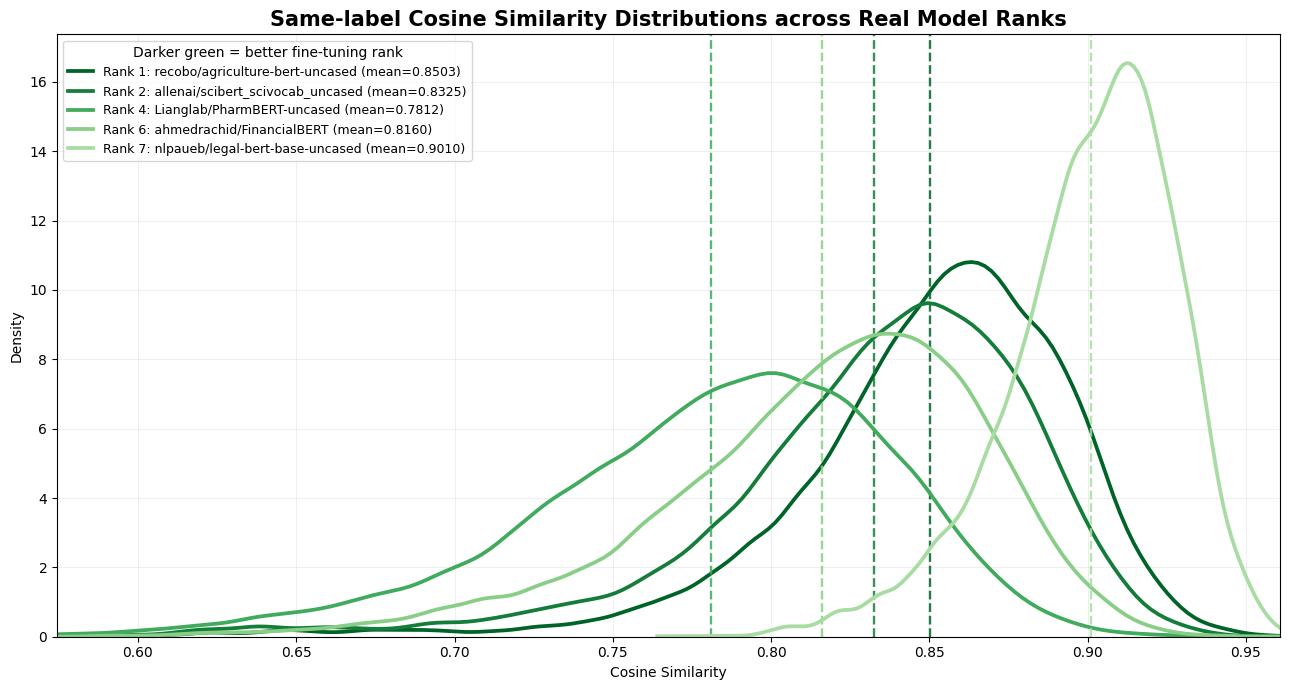

In [45]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "rheology_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

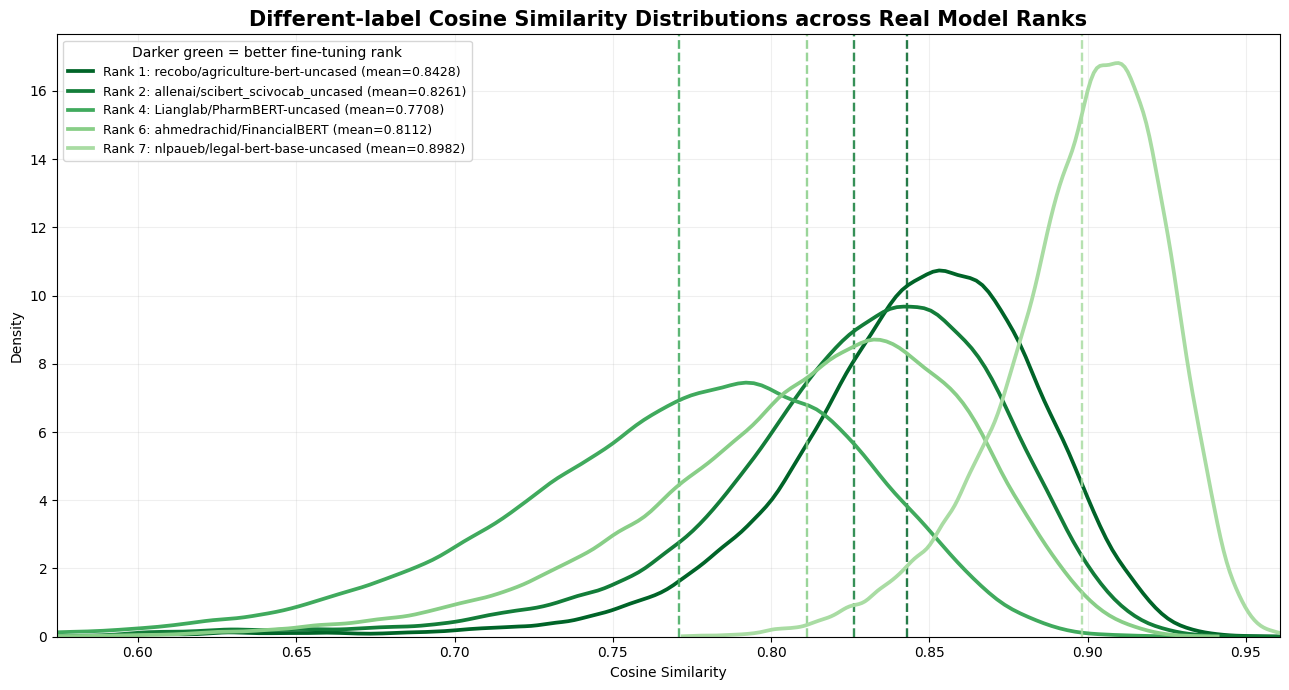

In [46]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        PLOT_DIR / "rheology_different_label_rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [47]:
def predict_model_ranking(metric_summary_df):
    # RankPredict 的列名，以及 grid search 得到的系数
    coefficients = {
        "same_mean_mean": -0.2,
        "diff_mean_mean": 0.2,
        "same_abs_eta_mean": -0.4,
        "diff_abs_eta_mean": 0.1,
        "chi2_distance_mean": -0.1,
    }

    result = metric_summary_df.copy()
    metrics = list(coefficients)

    # 在当前数据集的候选模型之间进行 Z-score 标准化
    values = result[metrics]
    std = values.std(ddof=0)

    scaled = (
        (values - values.mean())
        / std.mask(np.isclose(std, 0), 1.0)
    )

    # 线性组合：Score = Σ coefficient × standardized metric
    result["PredictionScore"] = (
        scaled.mul(pd.Series(coefficients))
        .sum(axis=1)
        .round(12)
    )

    result["PredictedRank"] = result["PredictionScore"].rank(
        ascending=False,
        method="average",
    )

    return result[
        ["model", "PredictionScore", "PredictedRank"]
    ].sort_values("PredictedRank")

In [48]:
predicted_ranking = predict_model_ranking(metric_summary_df)
display(predicted_ranking)

,model,PredictionScore,PredictedRank
6,recobo/chemical-bert-uncased,0.705489,1.0
3,google-bert/bert-base-uncased,0.236938,2.0
4,nlpaueb/legal-bert-base-uncased,0.018877,3.0
0,Lianglab/PharmBERT-uncased,-0.036992,4.0
1,ahmedrachid/FinancialBERT,-0.212431,5.0
5,recobo/agriculture-bert-uncased,-0.288114,6.0
2,allenai/scibert_scivocab_uncased,-0.423766,7.0
